# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'ratchev2'   # <-- set this
d = np.genfromtxt(f'../../labs/07/data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

264 epochs over 960 days; median quoted error 0.040 mag; rms of the light curve 0.214 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


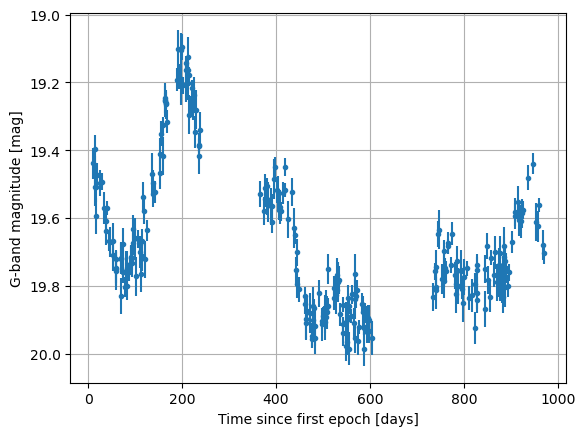

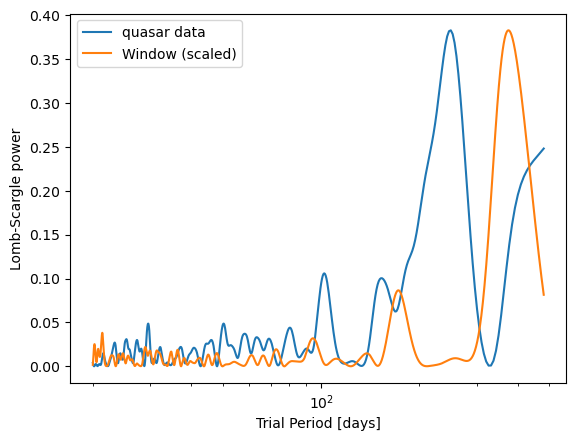

Highest peak [days]: 249.433
Power of highest peak: 0.383
False Alarm Probability: 2.83e-24


In [2]:
# Part 1: your work here
plt.errorbar(t, y, yerr = e, fmt = '.')
plt.gca().invert_yaxis()
plt.xlabel("Time since first epoch [days]")
plt.ylabel("G-band magnitude [mag]")
plt.grid()
plt.show()


ls = LombScargle(t, y, e)
f, p = ls.autopower(minimum_frequency = 2/T, maximum_frequency = 1/20, samples_per_peak = 20)
P = 1/f
idx_best = np.argmax(p)
P_best = P[idx_best]
alarm_prob = ls.false_alarm_probability(p[idx_best])

fw = np.linspace(2/T, 1/20, 60000)
pw = LombScargle(t, np.ones_like(y), fit_mean = False, center_data = False).power(fw)
plt.plot(P, p, label = "quasar data")
plt.plot(1 / fw, pw * p.max() / pw.max(), label = "Window (scaled)")
plt.xscale('log')
plt.xlabel("Trial Period [days]")
plt.ylabel("Lomb-Scargle power")
plt.legend()
plt.show()
print("Highest peak [days]:", round(P_best, 3))
print("Power of highest peak:", round(p[idx_best], 3))
print(f"False Alarm Probability: {alarm_prob:.3g}")

**ANSWER (a few sentences):**

The highest peak is at about 249.4 days with a false alarm probability of 2.83e-24. The sampling has a break between 240ish and 360ish days and another break between 610ish and 730ish days, corresponding to something close to a yearly pattern. The window function periodogram has a peak at around 375 days which could correspond to the close to annual relationship seen in this sampling, and an additional noticeable but smaller peak close to 172 days which arises from a less visually obvious distribution of the observation times. The smaller peak directly to the left of the 249.4 day highest peak at about 152 days is likely the annual alias at a higher frequency, which we can see by doing 1/(1/249.433 + 1/365.25) = 148.2 days (in fact, using the 375 day peal from the window function periodogram gives an even closer value of  1/(1/249.433 + 1/375) = 149.8 days). The other annual alias would be at 787 days which is off the plot since we stop at T/2. There is another peak in the data periodogram at about 102 days, and this could possibly be explained by the sampling, as the 172 day window periodogram peak gives an alias of 1/(1/249.433 + 1/172) = 101.8 days.

We do not search beyond T/2 because a trial period that is longer than half of the observing period is sampled for less than two cycles which means that basically any long trend could look like a periodic signal.

Astropy's false alarm probability assumes that we have white noise in which observations are independent. Our data (as can be seen by the plot of the data) is clearly correlated in time and so the false alarm probability is not reliable by itself, which means that the probability of this signal being a false alarm is likely much higher than the 2.83e-24 reported.

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ 0.340 (+0.296 / −0.132) mag, $\tau = $ 572.308 (+1445.839 / −360.016) d, $T/\tau = $ 1.678; the exponential kernel beats the squared exponential by $\Delta\ln L = $ 14.477; 35 of 50 held-out points are inside the 68% band.

In [3]:
# Part 2: your work here
def log_likelihood(theta, t_data = t, y_data = y, e_data = e, kernel = 'exp'):
    mu, log_sigma, log_tau = theta
    sigma = np.exp(log_sigma)
    tau = np.exp(log_tau)
    dt = np.abs(np.subtract.outer(t_data, t_data))

    if kernel == 'exp':
        Cov = sigma**2 * np.exp(-dt / tau)
    elif kernel == 'sqexp':
        Cov = sigma**2 * np.exp(-dt**2 / (2 * tau**2))
    Cov[np.diag_indices_from(Cov)] += e_data**2
    residuals = y_data - mu
    L, lower = cho_factor(Cov, lower = True)
    inv_res = cho_solve((L, lower), residuals)
    ln_C = 2 * np.sum(np.log(np.diag(L)))
    return -0.5 * (residuals @ inv_res + ln_C + len(y_data) * np.log(2 * np.pi))
def log_prior(theta):
    mu, log_sigma, log_tau = theta
    sigma = np.exp(log_sigma)
    tau = np.exp(log_tau)

    if not (0.01 < sigma < 3):
        return -np.inf
    if not (10 < tau < 4000):
        return -np.inf
    return 0.0
def log_posterior(theta):
    return log_likelihood(theta) + log_prior(theta)
def neg_log_posterior(theta):
    return -log_posterior(theta)

In [4]:
starting_vals = [[np.mean(y), np.log(0.1), np.log(100)], [np.mean(y), np.log(0.3), np.log(250)], [np.mean(y), np.log(0.5), np.log(500)], [np.mean(y), np.log(0.7), np.log(1000)], [np.mean(y), np.log(1.0), np.log(2000)]]
results = []
for i, start in enumerate(starting_vals):
    result = minimize(lambda theta: -log_likelihood(theta), start, method = "Nelder-Mead")
    results.append(result)

    print("Starting values", i)
    print("mu, log_sigma, log_tau:", np.round(result.x, 3))
    print("Max log-likelihood:", np.round(-result.fun, 3))
    print("")

Starting values 0
mu, log_sigma, log_tau: [19.631 -1.615  5.256]
Max log-likelihood: 375.883

Starting values 1
mu, log_sigma, log_tau: [19.631 -1.615  5.256]
Max log-likelihood: 375.883

Starting values 2
mu, log_sigma, log_tau: [19.631 -1.615  5.256]
Max log-likelihood: 375.883

Starting values 3
mu, log_sigma, log_tau: [19.631 -1.615  5.256]
Max log-likelihood: 375.883

Starting values 4
mu, log_sigma, log_tau: [19.631 -1.615  5.256]
Max log-likelihood: 375.883



In [5]:
%%time
theta_best = results[0].x
rng = np.random.default_rng(3)

h = 1e-4
n = len(theta_best)
hess = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        ei = np.zeros(n)
        ej = np.zeros(n)

        ei[i] = h
        ej[j] = h
        hess[i, j] = (-log_likelihood(theta_best + ei + ej) + log_likelihood(theta_best + ei - ej) + log_likelihood(theta_best - ei + ej) - log_likelihood(theta_best - ei - ej)) / (4 * h**2)

widths = np.sqrt(np.diag(np.linalg.inv(hess)))
rng = np.random.default_rng(3)
start_scale = 2 * widths
samplers = []
for k in range(4):
    theta_start = theta_best + start_scale * rng.normal(size = (16, 3))
    sampler = emcee.EnsembleSampler(nwalkers = 16, ndim = 3, log_prob_fn = log_posterior)
    sampler.run_mcmc(theta_start, 4000)
    samplers.append(sampler)

CPU times: total: 12min 39s
Wall time: 9min 36s


In [6]:
for k, sampler in enumerate(samplers):
    autocorr = sampler.get_autocorr_time()
    print("Sampler:", k)
    print("Autocorrelation Time:", np.round(autocorr, 3))
    print("Steps / autocorrelation Time:", np.round(5000 / autocorr, 1))
    print("Mean acceptance fraction:", np.round(np.mean(sampler.acceptance_fraction), 3))
    print("")

Sampler: 0
Autocorrelation Time: [40.628 60.004 60.996]
Steps / autocorrelation Time: [123.1  83.3  82. ]
Mean acceptance fraction: 0.599

Sampler: 1
Autocorrelation Time: [51.136 48.883 48.952]
Steps / autocorrelation Time: [ 97.8 102.3 102.1]
Mean acceptance fraction: 0.6

Sampler: 2
Autocorrelation Time: [54.807 52.489 50.895]
Steps / autocorrelation Time: [91.2 95.3 98.2]
Mean acceptance fraction: 0.602

Sampler: 3
Autocorrelation Time: [51.84  57.997 57.406]
Steps / autocorrelation Time: [96.4 86.2 87.1]
Mean acceptance fraction: 0.599



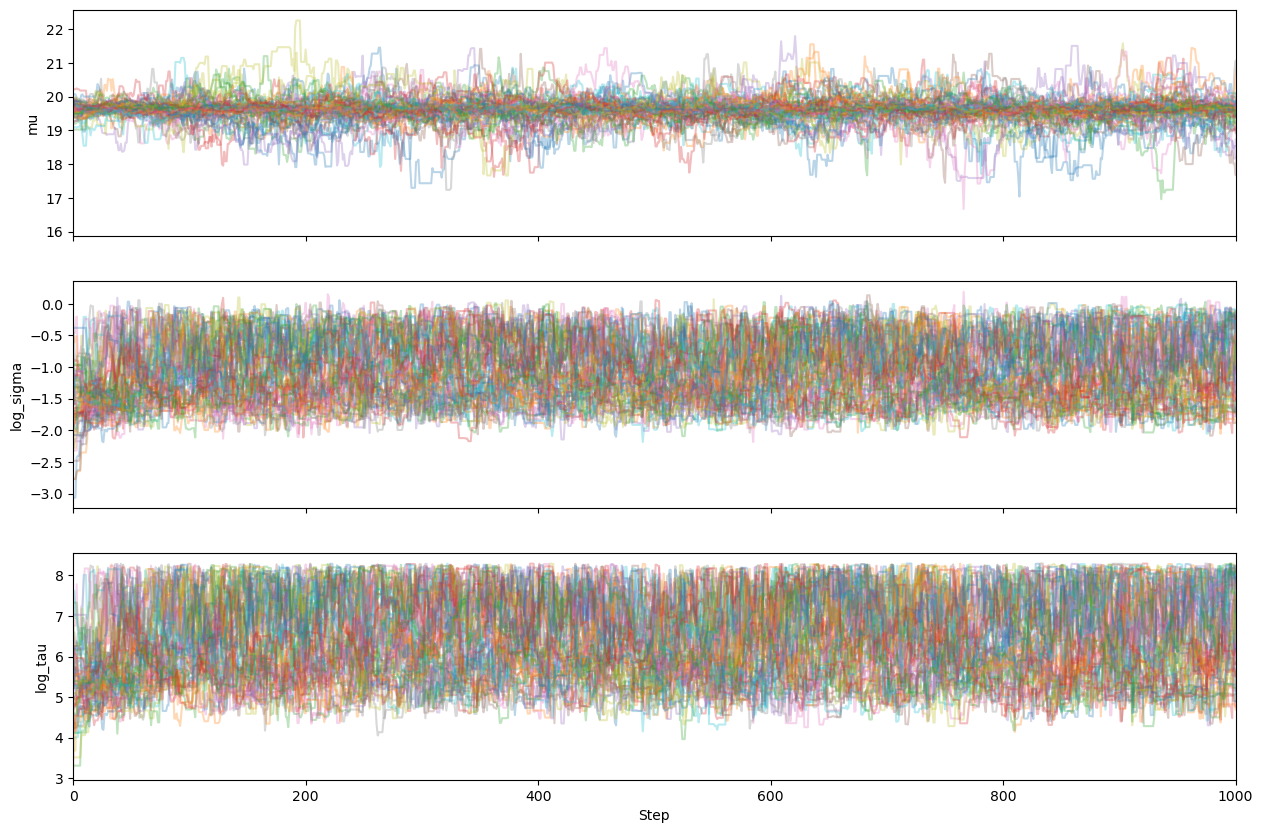

In [7]:
fig, axes = plt.subplots(3, figsize=(15, 10), sharex=True)
for k, sampler in enumerate(samplers):
    chain = sampler.get_chain()
    for i in range(3):
        axes[i].plot(chain[:, :, i], alpha=0.3)
axes[0].set_ylabel("mu")
axes[1].set_ylabel("log_sigma")
axes[2].set_ylabel("log_tau")
axes[-1].set_xlabel("Step")
plt.xlim(0, 1000)
plt.show()
burnin = 125

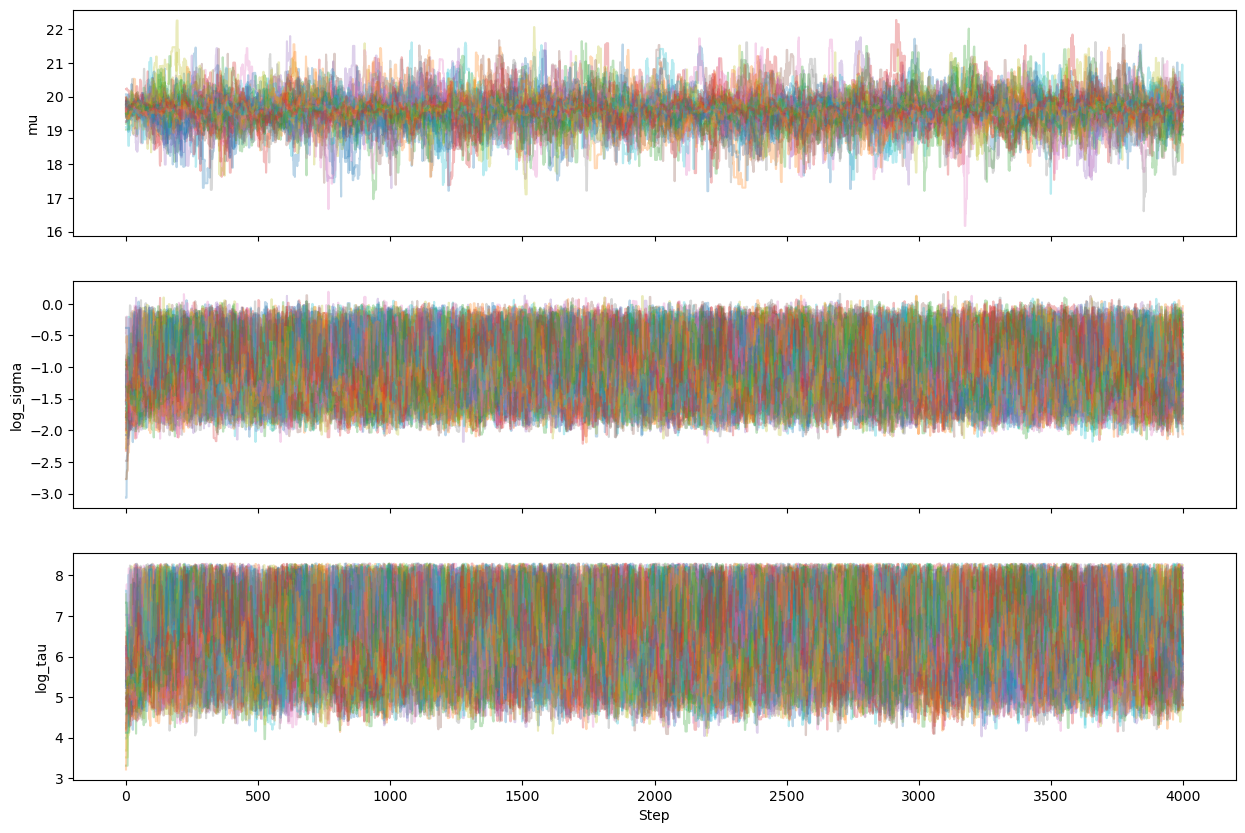

In [8]:
fig, axes = plt.subplots(3, figsize=(15, 10), sharex=True)
for k, sampler in enumerate(samplers):
    chain = sampler.get_chain()
    for i in range(3):
        axes[i].plot(chain[:, :, i], alpha=0.3)
axes[0].set_ylabel("mu")
axes[1].set_ylabel("log_sigma")
axes[2].set_ylabel("log_tau")
axes[-1].set_xlabel("Step")
plt.show()

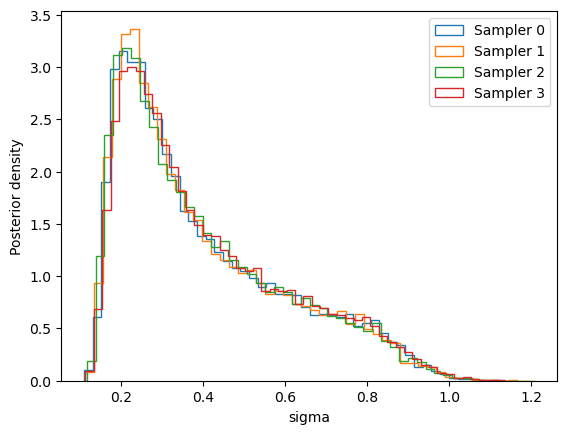

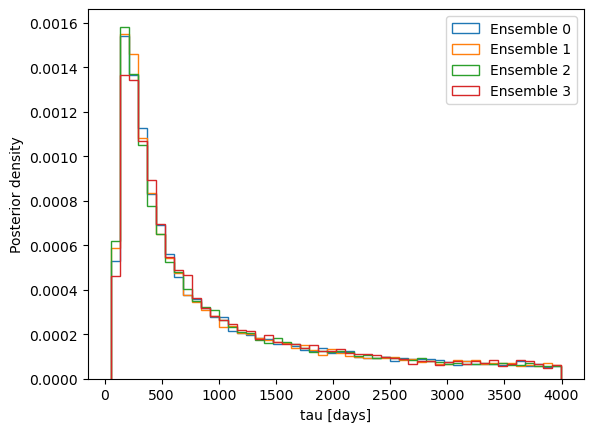

In [9]:
for k, sampler in enumerate(samplers):
    chain = sampler.get_chain(discard=burnin, flat=True)
    sigma_samples = np.exp(chain[:, 1])
    plt.hist(sigma_samples, bins=50, density=True, histtype="step", label=f"Sampler {k}")
plt.xlabel("sigma")
plt.ylabel("Posterior density")
plt.legend()
plt.show()

for k, sampler in enumerate(samplers):
    chain = sampler.get_chain(discard=burnin, flat=True)
    tau_samples = np.exp(chain[:, 2])
    plt.hist(tau_samples, bins=50, density=True, histtype="step", label=f"Ensemble {k}")
plt.xlabel("tau [days]")
plt.ylabel("Posterior density")
plt.legend()
plt.show()

In [10]:
samples = np.concatenate([sampler.get_chain(discard=burnin, flat=True) for sampler in samplers])
sigma_samples = np.exp(samples[:, 1])
tau_samples = np.exp(samples[:, 2])
T_tau_samples = T / tau_samples
sigma_16, sigma_50, sigma_84 = np.percentile(sigma_samples, [16, 50, 84])
tau_16, tau_50, tau_84 = np.percentile(tau_samples, [16, 50, 84])
T_tau_16, T_tau_50, T_tau_84 = np.percentile(T_tau_samples, [16, 50, 84])


print("T =", T, "days")

print("sigma =", round(sigma_50, 3), "+", round(sigma_84 - sigma_50, 3), "/ -", round(sigma_50 - sigma_16, 3))
print("tau =", round(tau_50, 3), "+", round(tau_84 - tau_50, 3), "/ -", round(tau_50 - tau_16, 3), "days")
print("T/tau =", round(T_tau_50, 3), "+", round(T_tau_84 - T_tau_50, 3), "/ -", round(T_tau_50 - T_tau_16, 3))

T = 960.317 days
sigma = 0.34 + 0.296 / - 0.132
tau = 572.308 + 1445.839 / - 360.016 days
T/tau = 1.678 + 2.846 / - 1.202


In [12]:
exp_min = minimize(lambda theta: -log_likelihood(theta, kernel='exp'), theta_best, method='Nelder-Mead')
expsq_min = minimize(lambda theta: -log_likelihood(theta, kernel='sqexp'), theta_best, method = 'Nelder-Mead')

lnL_exp = -exp_min.fun
lnL_sqexp = -expsq_min.fun

print("Exponential max ln L:", round(-exp_min.fun, 3))
print("Squared-exponential max ln L:", round(-expsq_min.fun, 3))
print("Diff:", round(abs(-exp_min.fun + expsq_min.fun), 3))

Exponential max ln L: 375.883
Squared-exponential max ln L: 361.406
Diff: 14.477


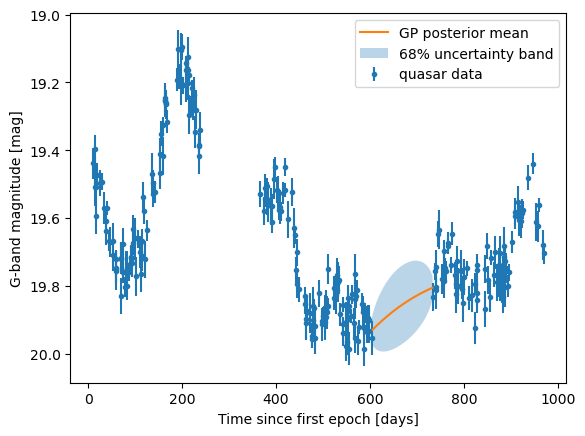

In [13]:
mu, log_sigma, log_tau = exp_min.x
sigma = np.exp(log_sigma)
tau = np.exp(log_tau)

gap_idx = np.argmax(np.diff(t))
t_left = t[gap_idx]
t_right = t[gap_idx + 1]

t_grid = np.linspace(t_left, t_right, 1000)
dt = np.abs(np.subtract.outer(t, t))
Cov = sigma**2 * np.exp(-dt / tau)
Cov[np.diag_indices_from(Cov)] += e**2
dt_s = np.abs(np.subtract.outer(t_grid, t))
Cov_s = sigma**2 * np.exp(-dt_s / tau)

c = cho_factor(Cov)
mean = mu + Cov_s @ cho_solve(c, y - mu)
var = sigma**2 - np.einsum('ij,ji->i', Cov_s, cho_solve(c, Cov_s.T))
sd = np.sqrt(var)

plt.errorbar(t, y, yerr=e, fmt='.', label='quasar data')
plt.plot(t_grid, mean, label='GP posterior mean')
plt.fill_between(t_grid, mean - sd, mean + sd, alpha=0.3, label='68% uncertainty band')
plt.xlabel("Time since first epoch [days]")
plt.ylabel("G-band magnitude [mag]")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [60]:
rand = np.random.default_rng(0)
finished = False
while not finished:
    start_t = np.sort(rand.uniform(t.min(), t.max() - 30, 4))
    if np.all(np.diff(start_t) >= 90):
        finished = True
        for i in range(len(start_t)):
            if not np.any((t >= start_t[i]) & (t <= start_t[i] + 30)):
                finished = False
                break
mask = np.zeros(len(t), dtype = bool)
for s in start_t:
    for i in range(len(t)):
        if t[i] >= s and t[i] <= s + 30:
            mask[i] = True
t_data, y_data, e_data = t[~mask], y[~mask], e[~mask]
t_mask, y_mask, e_mask = t[mask], y[mask], e[mask]
print("Number of held out points:", len(t_mask))

res_exp = minimize(lambda theta: -log_likelihood(theta, t_data, y_data, e_data, 'exp'), exp_min.x, method = 'Nelder-Mead')
mu_exp, log_sigma_exp, log_tau_exp = res_exp.x
sigma_exp, tau_exp = np.exp(log_sigma_exp), np.exp(log_tau_exp)
dt = np.abs(np.subtract.outer(t_data, t_data))
Cov_exp = sigma_exp**2 * np.exp(-dt / tau_exp)
Cov_exp[np.diag_indices_from(Cov_exp)] += e_data**2
dt_s = np.abs(np.subtract.outer(t_mask, t_data))
Cov_s_exp = sigma_exp**2 * np.exp(-dt_s / tau_exp)
c_exp = cho_factor(Cov_exp)
mean_exp = mu_exp + Cov_s_exp @ cho_solve(c_exp, y_data - mu_exp)
var_exp = sigma_exp**2 - np.einsum('ij,ji->i', Cov_s_exp, cho_solve(c_exp, Cov_s_exp.T))
sd_exp = np.sqrt(var_exp + e_mask**2)
inside_exp = (y_mask >= mean_exp - sd_exp) & (y_mask <= mean_exp + sd_exp)
r2_exp = 1 - np.sum((y_mask - mean_exp)**2) / np.sum((y_mask - np.mean(y_data))**2)

print("Exponential Kernel:")
print("Held-out points inside 68% band:", np.sum(inside_exp))
print("Fraction:", round(np.mean(inside_exp), 3))
print("R2:", round(r2_exp, 3))

res_sqexp = minimize(lambda theta: -log_likelihood(theta, t_data, y_data, e_data, 'sqexp'), expsq_min.x, method = 'Nelder-Mead')
mu_sqexp, log_sigma_sqexp, log_tau_sqexp = res_sqexp.x
sigma_sqexp, tau_sqexp = np.exp(log_sigma_sqexp), np.exp(log_tau_sqexp)
dt = np.abs(np.subtract.outer(t_data, t_data))
Cov_sqexp = sigma_sqexp**2 * np.exp(-dt**2 / (2 * tau_sqexp**2))
Cov_sqexp[np.diag_indices_from(Cov_sqexp)] += e_data**2
dt_s = np.abs(np.subtract.outer(t_mask, t_data))
Cov_s_sqexp = sigma_sqexp**2 * np.exp(-dt_s**2 / (2 * tau_sqexp**2))
c_sqexp = cho_factor(Cov_sqexp)
mean_sqexp = mu_sqexp + Cov_s_sqexp @ cho_solve(c_sqexp, y_data - mu_sqexp)
var_sqexp = sigma_sqexp**2 - np.einsum('ij,ji->i', Cov_s_sqexp, cho_solve(c_sqexp, Cov_s_sqexp.T))
sd_sqexp = np.sqrt(var_sqexp + e_mask**2)
inside_sqexp = (y_mask >= mean_sqexp - sd_sqexp) & (y_mask <= mean_sqexp + sd_sqexp)
r2_sqexp = 1 - np.sum((y_mask - mean_sqexp)**2) / np.sum((y_mask - np.mean(y_data))**2)

print("Squared Exponential Kernel:")
print("Held-out points inside 68% band:", np.sum(inside_sqexp))
print("Fraction:", round(np.mean(inside_sqexp), 3))
print("R2:", round(r2_sqexp, 3))

Number of held out points: 50
Exponential Kernel:
Held-out points inside 68% band: 35
Fraction: 0.7
R2: 0.812
Squared Exponential Kernel:
Held-out points inside 68% band: 23
Fraction: 0.46
R2: 0.823


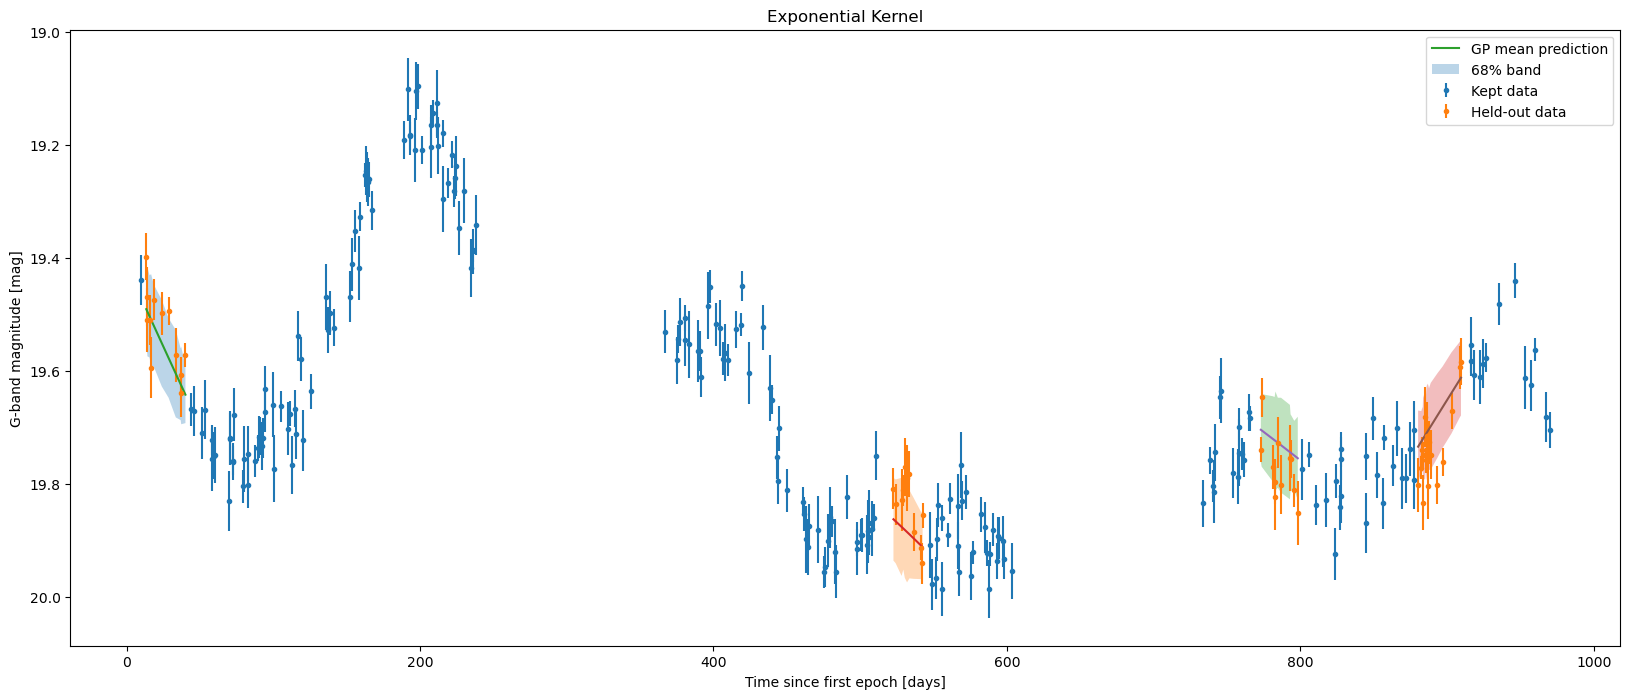

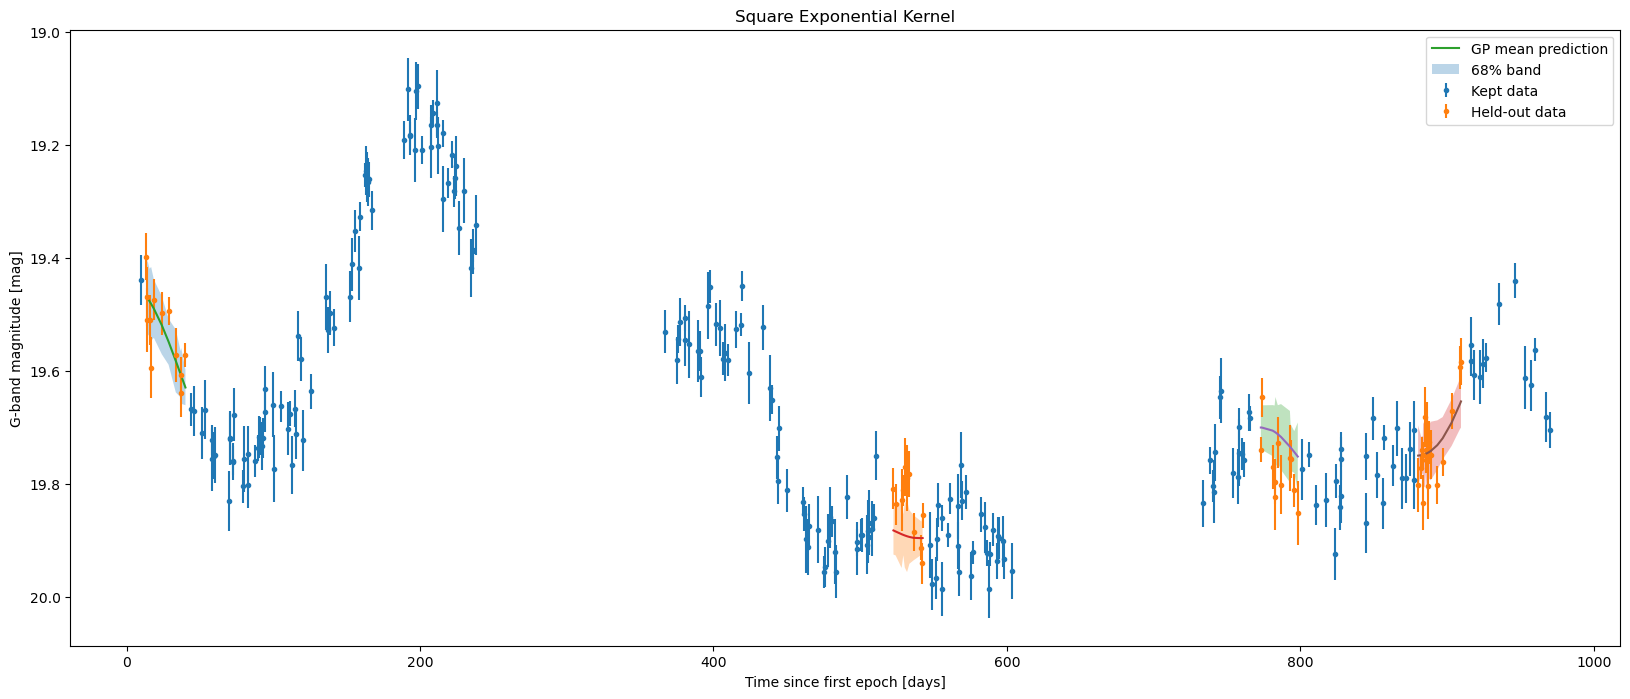

In [61]:
plt.figure(figsize = (20, 8))
plt.errorbar(t_data, y_data, yerr=e_data, fmt='.', label='Kept data')
plt.errorbar(t_mask, y_mask, yerr=e_mask, fmt='.', label='Held-out data')
for s in start_t:
    s_block = (t_mask >= s) & (t_mask <= s + 30)
    if s == start_t[0]:   
        plt.plot(t_mask[s_block], mean_exp[s_block], label='GP mean prediction')
        plt.fill_between(t_mask[s_block], mean_exp[s_block] - sd_exp[s_block], mean_exp[s_block] + sd_exp[s_block], alpha=0.3, label='68% band')
    else:
        plt.plot(t_mask[s_block], mean_exp[s_block])
        plt.fill_between(t_mask[s_block], mean_exp[s_block] - sd_exp[s_block], mean_exp[s_block] + sd_exp[s_block], alpha=0.3)
plt.xlabel("Time since first epoch [days]")
plt.ylabel("G-band magnitude [mag]")
plt.legend()
plt.title("Exponential Kernel")
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize = (20, 8))
plt.errorbar(t_data, y_data, yerr=e_data, fmt='.', label='Kept data')
plt.errorbar(t_mask, y_mask, yerr=e_mask, fmt='.', label='Held-out data')
for s in start_t:
    s_block = (t_mask >= s) & (t_mask <= s + 30)
    if s == start_t[0]:   
        plt.plot(t_mask[s_block], mean_sqexp[s_block], label='GP mean prediction')
        plt.fill_between(t_mask[s_block], mean_sqexp[s_block] - sd_sqexp[s_block], mean_sqexp[s_block] + sd_sqexp[s_block], alpha=0.3, label='68% band')
    else:
        plt.plot(t_mask[s_block], mean_sqexp[s_block])
        plt.fill_between(t_mask[s_block], mean_sqexp[s_block] - sd_sqexp[s_block], mean_sqexp[s_block] + sd_sqexp[s_block], alpha=0.3)
plt.xlabel("Time since first epoch [days]")
plt.ylabel("G-band magnitude [mag]")
plt.legend()
plt.title("Square Exponential Kernel")
plt.gca().invert_yaxis()
plt.show()

**FINAL ANSWER:** 

1. Choosing a uniform prior between ln(0.01) and ln(3) for ln(sigma) makes sense because it gives equal weight to different plausible values of the DRW amplitude, since we do not know what it is but expect it to be above 0 but not so extreme (above ln(3)) given the scale of the light curve. We have a uniform prior between 10 and 4000 days for tau as well that allows for timescales that are shorter and longer than the 1000-day observation windows. The bound on tau means that if our results suggest something close to 4000 days our data may not be able to determine how large tau really is and the bound may restrict our result. Similarly, the lower bound of the prior can force the model to overestimate the tau of shorter timescales than 10 days if they do exist.

2. I tried multiple different starting values for finding the max likelihood since I want to make sure that the optimizer does not get stuck in a local maxima at some particular start. All starts agreed so I took the results of the first start as the values to proceed with. I ran four independent MCMC samplers, each that had 16 walkers and 4k steps. I checked convergence by comparing the trace plots and posterior distributions, and both were consistent across the samplers. The estimated autocorrelation times were about 50 which gave 90+ steps / autocorrelation time. The mean acceptance fractions were about 0.6. All of these checks suggest that convergence was obtained. Tau is difficult to measure because T is comparable to the inferred timescale. This means that the light curve variations may not be visible enough within T to distinguish larger values of tau. This resulted in a very assymetric posterior as shown above with a very long tail toward larger timescales. Even though the peak of the posterior is closer to 200 days, the median is all the way at 628.72 days due to the assymmetry.

3. The exponential kernel had a higher max likelihood by 14.477 which suggests that the quasar light curve is better described by a less-smooth model (like the exponential) with more irregularities than by a smoother model (like the squared-exponential)

4. The band is for the latent curve rather than a new measurement. This is an important distinction because observed data points have their own measurement errors and so a band for a new measurement would have to include both the uncertainty in the latent light curve as well as the additional measurement noise, making the band wider.

5. The bands for both kernels look reasonable, with the exponential kernel having a number of points in the predictive band of 35/50 = 70% which is close to the expected 68%, and the squared exponential kernel being further away from this expectation with 46%. Both R^2 values are above 0.8 which indicates that the predictions explain the held out data pretty well. The lacking coverage of the squared exponential coverage sugests that its predictions dont adequately capture the variability in the data we held out which makes sense given our earlier argument about why a smoother model will struggle with such variable data.

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


1. I will use a p value threshold of 0.01 where I will only claim a period if I obtain a value below this. This would mean that fewer than 1% of the simulated curves produce a peak at least as high as that observed, which would indicate that the observed peak cannot be explained with a non periodic model and so this supports the presence of a periodic signal. 0.01 is chosen in particular because I want strong evidence before claiming a periodic signal.

In [69]:
%%time
# Part 3: your work here
from scipy.linalg import cholesky

ls = LombScargle(t, y, e)
f, p = ls.autopower(minimum_frequency = 2/T, maximum_frequency = 1/20, samples_per_peak = 20)
P = 1/f
idx_best = np.argmax(p)
P_best = P[idx_best]
p_best = p[idx_best]
alarm_prob = ls.false_alarm_probability(p[idx_best])

sim_peaks = np.zeros(10000)
mu_sim, log_sigma_sim, log_tau_sim = exp_min.x
sigma_sim = np.exp(log_sigma_sim)
tau_sim = np.exp(log_tau_sim)

dt = np.abs(np.subtract.outer(t, t))
Cov = sigma_sim**2 * np.exp(-dt / tau_sim)

L = cholesky(Cov, lower = True)

rng = np.random.default_rng(13)
for i in range(10000):
    z = rng.standard_normal(len(t))
    noise = rng.normal(0, e)
    y_sim = mu_sim + L @ z + noise
    ls_sim = LombScargle(t, y_sim, e)
    f_sim, p_sim = ls_sim.autopower(minimum_frequency = 2/T, maximum_frequency = 1/20, samples_per_peak = 20)
    sim_peaks[i] = np.max(p_sim)
p_val = (np.sum(sim_peaks >= p_best))  / 10000

print("Alarm prob from part 1:", alarm_prob)
print("emperical p-value:", p_val)

Alarm prob from part 1: 2.8346600548969345e-24
emperical p-value: 0.3838
CPU times: total: 29.9 s
Wall time: 30 s


In [76]:
periods = np.linspace(20, T / 2, 500)
Cov_sin = sigma_sim**2 * np.exp(-dt / tau_sim)
Cov_sin[np.diag_indices_from(Cov_sin)] += e**2
c_sin = cho_factor(Cov_sin)
C_inv_y = cho_solve(c_sin, y)

X_const = np.ones((len(t), 1))
C_inv_X_const = cho_solve(c_sin, X_const)
theta_const = np.linalg.solve(X_const.T @ C_inv_X_const, X_const.T @ C_inv_y)
resid_const = y - theta_const[0]
chi2_const = resid_const @ cho_solve(c_sin, resid_const)

delta_chi2 = np.zeros(len(periods))
for i, per in enumerate(periods):
   X = np.column_stack([np.ones(len(t)), np.cos(2 * np.pi * t / per), np.sin(2 * np.pi * t / per)])
   C_inv_X = cho_solve(c_sin, X)
   theta_hat = np.linalg.solve(X.T @ C_inv_X, X.T @ C_inv_y)
   resid_per = y - X @ theta_hat
   chi2_per = resid_per @ cho_solve(c_sin, resid_per)
   delta_chi2[i] = chi2_const - chi2_per
delta_chi2_best = np.max(delta_chi2)
best_P = periods[np.argmax(delta_chi2)]

print("Best period:", round(best_P, 3), "days")
print("Maximum delta chi squared:", round(delta_chi2_best, 3))

Best period: 187.833 days
Maximum delta chi squared: 17.092


In [84]:
%%time
sim_delta_chi2 = np.zeros(2000)
Cov = sigma_sim**2 * np.exp(-dt / tau_sim)
L = cholesky(Cov, lower =True)

rng = np.random.default_rng(13)
for j in range(2000):
    z = rng.standard_normal(len(t))
    noise = rng.normal(0, e)
    y_sim = mu_sim + L @ z + noise

    C_inv_y_sim = cho_solve(c_sin, y_sim)
    theta_const_sim = np.linalg.solve(X_const.T @ C_inv_X_const, X_const.T @ C_inv_y_sim)

    resid_const_sim = y_sim - theta_const_sim[0]
    chi2_const_sim = resid_const_sim @ cho_solve(c_sin, resid_const_sim)

    delta_chi2_sim = np.zeros(len(periods))
    for i, per in enumerate(periods):
        X = np.column_stack([np.ones(len(t)), np.cos(2 * np.pi * t / per), np.sin(2 * np.pi * t / per)])
        C_inv_X = cho_solve(c_sin, X)
        theta_hat = np.linalg.solve(X.T @ C_inv_X, X.T @ C_inv_y_sim)
        resid_per = y_sim - X @ theta_hat
        chi2_per = resid_per @ cho_solve(c_sin, resid_per)
        delta_chi2_sim[i] = chi2_const_sim - chi2_per
    sim_delta_chi2[j] = np.max(delta_chi2_sim)
p_val_sim = (np.sum(sim_delta_chi2 >= delta_chi2_best))  / 2000

CPU times: total: 4min 50s
Wall time: 4min 51s


In [86]:
%%time
tau_sim = tau_16
periods = np.linspace(20, T / 2, 500)
Cov_sin = sigma_sim**2 * np.exp(-dt / tau_sim)
Cov_sin[np.diag_indices_from(Cov_sin)] += e**2
c_sin = cho_factor(Cov_sin)
C_inv_y = cho_solve(c_sin, y)

X_const = np.ones((len(t), 1))
C_inv_X_const = cho_solve(c_sin, X_const)
theta_const = np.linalg.solve(X_const.T @ C_inv_X_const, X_const.T @ C_inv_y)
resid_const = y - theta_const[0]
chi2_const = resid_const @ cho_solve(c_sin, resid_const)

delta_chi2 = np.zeros(len(periods))
for i, per in enumerate(periods):
   X = np.column_stack([np.ones(len(t)), np.cos(2 * np.pi * t / per), np.sin(2 * np.pi * t / per)])
   C_inv_X = cho_solve(c_sin, X)
   theta_hat = np.linalg.solve(X.T @ C_inv_X, X.T @ C_inv_y)
   resid_per = y - X @ theta_hat
   chi2_per = resid_per @ cho_solve(c_sin, resid_per)
   delta_chi2[i] = chi2_const - chi2_per
delta_chi2_best = np.max(delta_chi2)
best_P = periods[np.argmax(delta_chi2)]
sim_delta_chi2 = np.zeros(2000)
Cov = sigma_sim**2 * np.exp(-dt / tau_sim)
L = cholesky(Cov, lower =True)

rng = np.random.default_rng(13)
for j in range(2000):
    z = rng.standard_normal(len(t))
    noise = rng.normal(0, e)
    y_sim = mu_sim + L @ z + noise

    C_inv_y_sim = cho_solve(c_sin, y_sim)
    theta_const_sim = np.linalg.solve(X_const.T @ C_inv_X_const, X_const.T @ C_inv_y_sim)

    resid_const_sim = y_sim - theta_const_sim[0]
    chi2_const_sim = resid_const_sim @ cho_solve(c_sin, resid_const_sim)

    delta_chi2_sim = np.zeros(len(periods))
    for i, per in enumerate(periods):
        X = np.column_stack([np.ones(len(t)), np.cos(2 * np.pi * t / per), np.sin(2 * np.pi * t / per)])
        C_inv_X = cho_solve(c_sin, X)
        theta_hat = np.linalg.solve(X.T @ C_inv_X, X.T @ C_inv_y_sim)
        resid_per = y_sim - X @ theta_hat
        chi2_per = resid_per @ cho_solve(c_sin, resid_per)
        delta_chi2_sim[i] = chi2_const_sim - chi2_per
    sim_delta_chi2[j] = np.max(delta_chi2_sim)
p_val_sim_lower = (np.sum(sim_delta_chi2 >= delta_chi2_best))  / 2000

CPU times: total: 5min 19s
Wall time: 5min 20s


In [104]:
%%time
tau_sim = tau_84
periods = np.linspace(20, T / 2, 500)
Cov_sin = sigma_sim**2 * np.exp(-dt / tau_sim)
Cov_sin[np.diag_indices_from(Cov_sin)] += e**2 + 1e-10
c_sin = cho_factor(Cov_sin, lower = True)
C_inv_y = cho_solve(c_sin, y)

X_const = np.ones((len(t), 1))
C_inv_X_const = cho_solve(c_sin, X_const)
theta_const = np.linalg.solve(X_const.T @ C_inv_X_const, X_const.T @ C_inv_y)
resid_const = y - theta_const[0]
chi2_const = resid_const @ cho_solve(c_sin, resid_const)

delta_chi2 = np.zeros(len(periods))
for i, per in enumerate(periods):
   X = np.column_stack([np.ones(len(t)), np.cos(2 * np.pi * t / per), np.sin(2 * np.pi * t / per)])
   C_inv_X = cho_solve(c_sin, X)
   theta_hat = np.linalg.solve(X.T @ C_inv_X, X.T @ C_inv_y)
   resid_per = y - X @ theta_hat
   chi2_per = resid_per @ cho_solve(c_sin, resid_per)
   delta_chi2[i] = chi2_const - chi2_per
delta_chi2_best = np.max(delta_chi2)
best_P = periods[np.argmax(delta_chi2)]
sim_delta_chi2 = np.zeros(3000)
Cov = sigma_sim**2 * np.exp(-dt / tau_sim)
Cov[np.diag_indices_from(Cov)] += 1e-10
L = cholesky(Cov, lower = True)

rng = np.random.default_rng(13)
for j in range(3000):
    z = rng.standard_normal(len(t))
    noise = rng.normal(0, e)
    y_sim = mu_sim + L @ z + noise

    C_inv_y_sim = cho_solve(c_sin, y_sim)
    theta_const_sim = np.linalg.solve(X_const.T @ C_inv_X_const, X_const.T @ C_inv_y_sim)

    resid_const_sim = y_sim - theta_const_sim[0]
    chi2_const_sim = resid_const_sim @ cho_solve(c_sin, resid_const_sim)

    delta_chi2_sim = np.zeros(len(periods))
    for i, per in enumerate(periods):
        X = np.column_stack([np.ones(len(t)), np.cos(2 * np.pi * t / per), np.sin(2 * np.pi * t / per)])
        C_inv_X = cho_solve(c_sin, X)
        theta_hat = np.linalg.solve(X.T @ C_inv_X, X.T @ C_inv_y_sim)
        resid_per = y_sim - X @ theta_hat
        chi2_per = resid_per @ cho_solve(c_sin, resid_per)
        delta_chi2_sim[i] = chi2_const_sim - chi2_per
    sim_delta_chi2[j] = np.max(delta_chi2_sim)
p_val_sim_upper = (np.sum(sim_delta_chi2 >= delta_chi2_best))  / 3000

CPU times: total: 7min 36s
Wall time: 7min 37s


In [105]:
print("P value from chi2:", p_val_sim)
print("P value lower end of tau interval:", p_val_sim_lower)
print("P value upper end of tau interval:", p_val_sim_upper)

P value from chi2: 0.016
P value lower end of tau interval: 0.006
P value upper end of tau interval: 0.0


**ANSWER (the decision rule first, then the verdict):**

2. I simulated 10k DRW light curves, giving a p-value of 0.3838, while the astropy false alarm probability was on the order of e-24 which is much smaller. This difference is because astropy's false alarm probability assumes uncorrelated Gaussian noise which is clearly not true for a random walk compared to the DRW process which accounts for correlated variability. These differences in the assumed noise model make all the difference.

3/4. The Lomb-Scargle peak had an empirical p-value of p = 0.3838. The sinusoidal chi2 test gave p = 0.016 at the maximum likelihood tau, p = 0.006 at the lower end of the tau interval, and p = 0 in the higher endpoint (this is not actually p=0 but instead just zero exceedances in 3000 simulations). Since the result depends very strongly on tau, and multiple of these values are above the p=0.01 threshold I set before doing this analysis, I would argue that the periodicity is not established well. I would need to instead see these values stay below p = 0.01 and not have such large differences between them. My recommendation is that the team should not announce a binary candidate on this evidence alone.

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


Demonstration 1
AI Lomb-Scargle false alarm probability: 2.8346600548969345e-24
Empirical p-value from my simulations: 0.3838

Demonstration 2



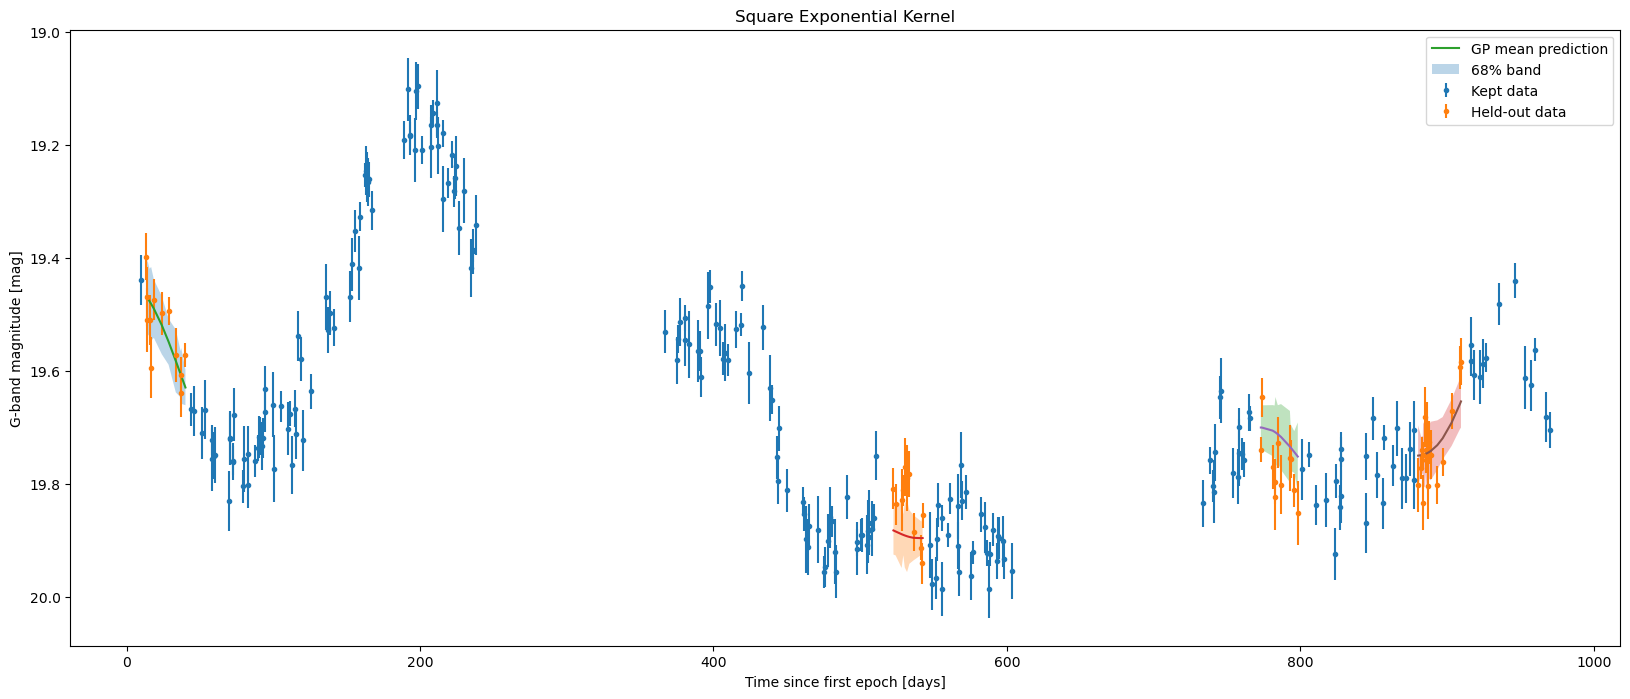

Demonstration 3


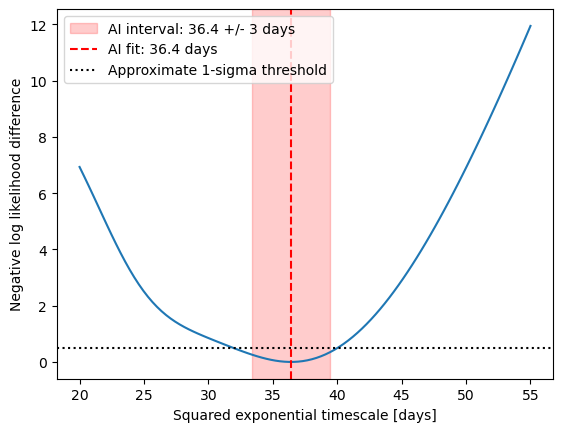

In [99]:
# Part 4: your work here
print("Demonstration 1")
print("AI Lomb-Scargle false alarm probability:", alarm_prob)
print("Empirical p-value from my simulations:", p_val)
print("")

print("Demonstration 2")
print("")
plt.figure(figsize = (20, 8))
plt.errorbar(t_data, y_data, yerr=e_data, fmt='.', label='Kept data')
plt.errorbar(t_mask, y_mask, yerr=e_mask, fmt='.', label='Held-out data')
for s in start_t:
    s_block = (t_mask >= s) & (t_mask <= s + 30)
    if s == start_t[0]:   
        plt.plot(t_mask[s_block], mean_sqexp[s_block], label='GP mean prediction')
        plt.fill_between(t_mask[s_block], mean_sqexp[s_block] - sd_sqexp[s_block], mean_sqexp[s_block] + sd_sqexp[s_block], alpha=0.3, label='68% band')
    else:
        plt.plot(t_mask[s_block], mean_sqexp[s_block])
        plt.fill_between(t_mask[s_block], mean_sqexp[s_block] - sd_sqexp[s_block], mean_sqexp[s_block] + sd_sqexp[s_block], alpha=0.3)
plt.xlabel("Time since first epoch [days]")
plt.ylabel("G-band magnitude [mag]")
plt.legend()
plt.title("Square Exponential Kernel")
plt.gca().invert_yaxis()
plt.show()
print("Demonstration 3")
tau_grid = np.linspace(20, 55, 100)
profile_nll = []

for tau in tau_grid:
    result = minimize(lambda x: -log_likelihood([x[0], x[1], np.log(tau)], kernel='sqexp'),x0=[np.mean(y), np.log(np.std(y))],method='Nelder-Mead')
    profile_nll.append(result.fun)

profile_nll = np.array(profile_nll)
profile_nll -= profile_nll.min()

plt.plot(tau_grid, profile_nll)
plt.axvspan(33.4, 39.4, color='red', alpha=0.2, label='AI interval: 36.4 +/- 3 days')
plt.axvline(36.4, color='red', linestyle='--', label='AI fit: 36.4 days')
plt.axhline(0.5, color='black', linestyle=':', label='Approximate 1-sigma threshold')
plt.xlabel('Squared exponential timescale [days]')
plt.ylabel('Negative log likelihood difference')
plt.legend()
plt.show()

**REFEREE REPORT:**

FLAW 1: The AI reports the Lomb-Scargle false-alarm probability as the reason for a highly significant period being present, but this is the incorrect treatment as the false alarm probability ignores the correlated variability of the data and assumes an uncorrelated Gaussian noise, making this not a trustable p value. This is demonstrated in Demonstration 1 where I print out the false alarm probability and then the p value I calculated in part 3 using GP simulations of the periodogram in comparison to the original data. We can see that this error results in having a confidence in the period peak that is much higher than it should be, as the p value is changed drastically. The correct treatment is as we did in part 3, where we simulated DRW light curves with the observed measurement errors and compared the maximum peaks with the observed maximum to see if the natural variability of the data can create a peak as high as that originally seen.

FLAW 2: The AI claims that "quasar variability on these time scales is smooth" which we showed in our analysis above in Part 2 to not be true. This is demonstrated in the plot in Demonstration 2 which I reproduced from Part 2 that shows with the use of held out points that the squared exponential is not able to capture the variability in the data. We can see that many more than the (100-68)=34% of points are outside of the 68% predictive band, which demonstrates this error. The correct treatment is to instead use an exponential, check that it is the better model using the log likelihood, and ensure that the 68% predictive band is in fact close to 68% as a result.

FLAW 3: The AI uses the local curvature of the negative log likelihood in order to get an uncertainty on the timescale. This makes the assumption that it is approximately parabolic near the minimum, which may not be true especially given the very non symmetric posteriors I obtained in the earlier parts of my analysis. This is therefore not a safe assumption to make without justification. The demonstation evaluates the likelihood over a grid of timescales (optimizing the other parameters at each point) and plots the resulting profile with the AI's uncertainty interval marked. As can be seen in demonstration 3, this demonstration came out negative as the curvature is in fact approximately parabolic and the symmetric error bars describe the uncertainty well. For this error to have moved the numbers, the result would have had to have been more assymetric similar to the exponential result I obtained in part 2, and in that case making such an assumption without checking would have been quite bad. The correct treatment is to use a grid, monte Carlo, or other method to verify the curvature before making an assumption about the uncertainty. Overall, this demonstration reveals a weakness in the AI's methodology, but this didn't end up actually mattering for the current data.

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [ ]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


In [ ]:
# Part 5: your work here

**ANSWER (the criterion first, then the result):**

DIDN'T COMPLETE THIS PART.

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

I did not use any AI for this

**REFLECTION:**

As I didn't use any AI, this is not applicable

**VERIFICATION PLAN:**

For part 2, I checked that the maximum-likelihood optimization converged to consistent results from different initial parameter values to make sure I was not getting stuck in a local maxima. A failure here would have looked like getting different maximum likelihood values for the different starts. I also assessed the MCMC convergence using trace plots, autocorrelation times, effective sample counts, posterior distributions, and mean acceptance fractions, and used 4 different samplers which I compared and compiled the results of. Failure would have looked like chains that did not mix, autocorrelation times that were too long relative to chain length, substantially different posterior distributions from one sampler to another, or very low or high mean acceptance fractions. 

For part 3, when doing the simulations, I steadily increased the count of simulations and observed how the p-value changed and made sure that it stayed significantly above or below the 0.01 threshold I decided. Failure would have looked like estimated p-values substantially changing as the number of simulations increased, but this was not observed.